# 06 — Validated Final Retraining

## Robustness-Enhanced Vision-Language-Action Learning for Generalizable Robotic Manipulation

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Initialization:** `lerobot/smolvla_base`

---

## Notebook objective

Notebook 05 and Notebook 05b completed the training-regime investigation.

The training budget is now **frozen**. This notebook does **not** perform additional hyperparameter search, checkpoint selection, or OOD-based model selection.

Its role is to create the final controlled model set required for the definitive robustness experiment:

| Variant | Final seeds | Training condition | Role |
|---|---:|---|---|
| **M1** | 42, 123, 2026 | Original language + original images | Standard control |
| **M2-L** | 42 | L0/L1/L2 language variation | Language ablation |
| **M2-E** | 42 | Photometric augmentation | Environmental ablation |
| **M2-LE** | 42, 123, 2026 | L0/L1/L2 + photometric augmentation | Main proposed robustness model |

The validated M1 checkpoints generated during Notebook 05b are **reused**. Only the five robustness models are trained here.

### Scientific boundary

Notebook 06 answers:

> **Can all final robustness variants be trained under exactly the same frozen optimization budget and serialized as a reproducible final checkpoint set?**

It does **not** answer whether M2-LE is better than M1.

That question remains reserved for **Notebook 07 — Definitive Robustness Evaluation**.

## 1. Frozen experimental contract

Notebook 06 treats the Notebook 05b handoff as an immutable experimental contract.

The following are not tuned here:

- final training-step budget,
- learning rate,
- weight decay,
- batch size,
- trainability scope,
- learning-rate schedule,
- dataset split,
- base-model revision,
- language perturbation definitions,
- environmental augmentation ranges.

Only the intended robustness factor changes between model variants.

### Robustness interventions retained from Notebook 03

**Language augmentation**

- M2-L and M2-LE use L0, L1 and L2.
- Assignment is deterministic, seed-dependent and balanced within each LIBERO task.
- L3 remains completely held out from training.

**Environmental augmentation**

M2-E and M2-LE use conservative photometric augmentation only:

- brightness `[0.85, 1.15]`
- contrast `[0.85, 1.15]`
- saturation `[0.85, 1.15]`
- maximum two transforms per image
- random transform order
- no geometric transformation

No OOD evaluation result is used anywhere in this notebook.

## 2. Environment, paths and final-budget handoff

In [2]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from copy import deepcopy
from datetime import datetime
import gc
import hashlib
import json
import math
import random
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Dataset, Subset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATASET_REPO_ID = "lerobot/libero"
BASE_MODEL_REPO_ID = "lerobot/smolvla_base"
VIDEO_BACKEND = "pyav"

GRAD_CLIP_NORM = 10.0
LOG_EVERY = 100

PRIMARY_SEEDS = [
    42,
    123,
    2026,
]


def find_repo_root(start: Path) -> Path:
    current = start.resolve()

    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate

    if current.name == "notebooks":
        return current.parent

    return current


REPO_ROOT = find_repo_root(
    Path.cwd()
)

RESULTS_DIR = (
    REPO_ROOT
    / "results"
)

METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
    / "validated_final_retraining"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
    / "validated_final_retraining"
)

FINAL_TRAINING_DIR = (
    REPO_ROOT
    / "experiments"
    / "validated_final_retraining"
)

EXPERIMENT_CONFIG_DIR = (
    REPO_ROOT
    / "configs"
    / "experiments"
)

for directory in [
    METRICS_DIR,
    FIGURES_DIR,
    FINAL_TRAINING_DIR,
    EXPERIMENT_CONFIG_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            [
                "git",
                "rev-parse",
                "HEAD",
            ],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None


PROJECT_GIT_SHA = git_sha(
    REPO_ROOT
)


NOTEBOOK02_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "robustness_training"
    / "notebook02_summary.json"
)

NOTEBOOK03_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "tuning_final_training"
    / "notebook03_summary.json"
)

NOTEBOOK05B_HANDOFF_PATH = (
    EXPERIMENT_CONFIG_DIR
    / "notebook06_final_budget_handoff_v2.json"
)

for required_path in [
    NOTEBOOK02_SUMMARY_PATH,
    NOTEBOOK03_SUMMARY_PATH,
    NOTEBOOK05B_HANDOFF_PATH,
]:
    assert required_path.exists(), (
        f"Required prerequisite artifact missing: {required_path}"
    )


with open(
    NOTEBOOK02_SUMMARY_PATH,
    "r",
) as f:
    notebook02_summary = json.load(
        f
    )


with open(
    NOTEBOOK03_SUMMARY_PATH,
    "r",
) as f:
    notebook03_summary = json.load(
        f
    )


with open(
    NOTEBOOK05B_HANDOFF_PATH,
    "r",
) as f:
    final_budget_handoff = json.load(
        f
    )


assert notebook02_summary[
    "status"
] == "PASS"

assert notebook03_summary[
    "status"
] == "PASS"

assert final_budget_handoff[
    "final_budget_frozen"
] is True

assert final_budget_handoff[
    "no_further_budget_search"
] is True

assert final_budget_handoff[
    "budget_selection_used_ood_results"
] is False

assert final_budget_handoff[
    "training_scope"
] == "standard"


FINAL_TRAINING_STEPS = int(
    final_budget_handoff[
        "final_training_steps"
    ]
)

LEARNING_RATE = float(
    final_budget_handoff[
        "optimizer"
    ][
        "learning_rate"
    ]
)

WEIGHT_DECAY = float(
    final_budget_handoff[
        "optimizer"
    ][
        "weight_decay"
    ]
)

BATCH_SIZE = int(
    final_budget_handoff[
        "optimizer"
    ][
        "batch_size"
    ]
)

WARMUP_STEPS = int(
    final_budget_handoff[
        "scheduler"
    ][
        "warmup_steps"
    ]
)

DECAY_END_STEP = int(
    final_budget_handoff[
        "scheduler"
    ][
        "cosine_decay_end_step"
    ]
)

MIN_LR_RATIO = float(
    final_budget_handoff[
        "scheduler"
    ][
        "min_lr_ratio"
    ]
)


environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "final_training_steps": FINAL_TRAINING_STEPS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "warmup_steps": WARMUP_STEPS,
    "decay_end_step": DECAY_END_STEP,
    "min_lr_ratio": MIN_LR_RATIO,
}

display(
    pd.DataFrame(
        [environment_summary]
    ).T.rename(
        columns={0: "Value"}
    )
)

assert torch.cuda.is_available(), (
    "Notebook 06 final training requires the validated CUDA environment."
)

print("FINAL-BUDGET HANDOFF + ENVIRONMENT: PASS")

,Value
python,3.12.14
torch,2.11.0+cu128
cuda_available,True
device,cuda
gpu,NVIDIA GeForce RTX 5090
project_git_sha,bf3d723e97e3e95b5b0d391efe9e13184f620a05
final_training_steps,25000
learning_rate,0.0001
weight_decay,0.01
batch_size,4


FINAL-BUDGET HANDOFF + ENVIRONMENT: PASS


## 3. Audit the frozen final model plan

In [3]:
expected_final_models = {
    "M1": {
        "seeds": [
            42,
            123,
            2026,
        ],
        "reuse_validated_checkpoints": True,
        "language_levels": [
            "L0",
        ],
        "environment_augmentation": False,
    },
    "M2-L": {
        "seeds": [
            42,
        ],
        "reuse_validated_checkpoints": False,
        "language_levels": [
            "L0",
            "L1",
            "L2",
        ],
        "environment_augmentation": False,
    },
    "M2-E": {
        "seeds": [
            42,
        ],
        "reuse_validated_checkpoints": False,
        "language_levels": [
            "L0",
        ],
        "environment_augmentation": True,
    },
    "M2-LE": {
        "seeds": [
            42,
            123,
            2026,
        ],
        "reuse_validated_checkpoints": False,
        "language_levels": [
            "L0",
            "L1",
            "L2",
        ],
        "environment_augmentation": True,
    },
}


assert final_budget_handoff[
    "final_models"
] == expected_final_models


plan_rows = []

for variant, config in expected_final_models.items():
    for seed in config[
        "seeds"
    ]:
        plan_rows.append({
            "variant": variant,
            "seed": int(
                seed
            ),
            "training_steps": (
                FINAL_TRAINING_STEPS
            ),
            "language_levels": (
                "/".join(
                    config[
                        "language_levels"
                    ]
                )
            ),
            "environment_augmentation": (
                bool(
                    config[
                        "environment_augmentation"
                    ]
                )
            ),
            "checkpoint_source": (
                "Notebook 05b reuse"
                if config[
                    "reuse_validated_checkpoints"
                ]
                else "Notebook 06 train"
            ),
        })


final_model_plan_df = pd.DataFrame(
    plan_rows
)

display(
    final_model_plan_df
)

assert len(
    final_model_plan_df
) == 8

assert (
    final_model_plan_df[
        "checkpoint_source"
    ]
    == "Notebook 06 train"
).sum() == 5

print(
    "Final model count :",
    len(
        final_model_plan_df
    ),
)

print(
    "New training runs :",
    int(
        (
            final_model_plan_df[
                "checkpoint_source"
            ]
            == "Notebook 06 train"
        ).sum()
    ),
)

print("FINAL MODEL PLAN: FROZEN")

,variant,seed,training_steps,language_levels,environment_augmentation,checkpoint_source
0,M1,42,25000,L0,False,Notebook 05b reuse
1,M1,123,25000,L0,False,Notebook 05b reuse
2,M1,2026,25000,L0,False,Notebook 05b reuse
3,M2-L,42,25000,L0/L1/L2,False,Notebook 06 train
4,M2-E,42,25000,L0,True,Notebook 06 train
5,M2-LE,42,25000,L0/L1/L2,True,Notebook 06 train
6,M2-LE,123,25000,L0/L1/L2,True,Notebook 06 train
7,M2-LE,2026,25000,L0/L1/L2,True,Notebook 06 train


Final model count : 8
New training runs : 5
FINAL MODEL PLAN: FROZEN


## 4. Load the frozen split and deterministic language specification

The language table is inherited from Notebook 02 and contains 10 LIBERO-Spatial tasks × 4 language levels.

Only L0/L1/L2 are trainable.

L3 remains held out.

In [4]:
DATASET_REVISION = (
    final_budget_handoff[
        "dataset_revision"
    ]
)

BASE_MODEL_REVISION = (
    final_budget_handoff[
        "base_model_revision"
    ]
)

frozen_split_path = (
    REPO_ROOT
    / final_budget_handoff[
        "split_file"
    ]
)

language_table_path = (
    REPO_ROOT
    / notebook02_summary[
        "language_table"
    ]
)

assert frozen_split_path.exists()
assert language_table_path.exists()


frozen_split_df = pd.read_csv(
    frozen_split_path
)

language_df = pd.read_csv(
    language_table_path
)


frozen_split_df[
    "split"
] = (
    frozen_split_df[
        "split"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
    .replace({
        "val": "validation",
        "valid": "validation",
    })
)


train_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df[
            "split"
        ]
        == "train",
        "episode_index",
    ]
    .astype(int)
    .tolist()
)

validation_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df[
            "split"
        ]
        == "validation",
        "episode_index",
    ]
    .astype(int)
    .tolist()
)


assert len(
    train_ids
) == 346

assert len(
    validation_ids
) == 86

assert set(
    train_ids
).isdisjoint(
    validation_ids
)

assert len(
    language_df
) == 40

assert language_df[
    "task_id"
].nunique() == 10

assert set(
    language_df[
        "level"
    ]
) == {
    "L0",
    "L1",
    "L2",
    "L3",
}

if "semantic_review" in language_df.columns:
    assert (
        language_df[
            "semantic_review"
        ]
        == "PASS"
    ).all()


display(
    language_df[
        [
            "task_id",
            "level",
            "augmented_instruction",
        ]
    ].head(
        12
    )
)

print(
    "Training episodes   :",
    len(
        train_ids
    ),
)

print(
    "Validation episodes :",
    len(
        validation_ids
    ),
)

print("FROZEN SPLIT + LANGUAGE TABLE: PASS")

,task_id,level,augmented_instruction
0,30,L0,pick up the black bowl next to the cookie box ...
1,30,L1,pick up the black bowl beside the cookie box a...
2,30,L2,place the black bowl that is next to the cooki...
3,30,L3,move the black bowl positioned beside the cook...
4,31,L0,pick up the black bowl in the top drawer of th...
5,31,L1,take the black bowl from the top drawer of the...
6,31,L2,"from the wooden cabinet's top drawer, pick up ..."
7,31,L3,retrieve the black bowl stored in the upper dr...
8,32,L0,pick up the black bowl on the ramekin and plac...
9,32,L1,pick up the black bowl sitting on the ramekin ...


Training episodes   : 346
Validation episodes : 86
FROZEN SPLIT + LANGUAGE TABLE: PASS


## 5. Reconstruct the frozen SmolVLA configuration and validation subset

In [5]:
from huggingface_hub import snapshot_download

from lerobot.configs import FeatureType
from lerobot.datasets import (
    LeRobotDataset,
    LeRobotDatasetMetadata,
)
from lerobot.datasets.factory import (
    resolve_delta_timestamps,
)
from lerobot.policies import (
    make_pre_post_processors,
)
from lerobot.policies.smolvla.configuration_smolvla import (
    SmolVLAConfig,
)
from lerobot.policies.smolvla.modeling_smolvla import (
    SmolVLAPolicy,
)
from lerobot.transforms import (
    ImageTransformConfig,
    ImageTransforms,
    ImageTransformsConfig,
)
from lerobot.utils.collate import (
    lerobot_collate_fn,
)
from lerobot.utils.feature_utils import (
    dataset_to_policy_features,
)


BASE_MODEL_SNAPSHOT = Path(
    snapshot_download(
        repo_id=BASE_MODEL_REPO_ID,
        revision=BASE_MODEL_REVISION,
    )
)


dataset_meta = (
    LeRobotDatasetMetadata(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
    )
)


policy_features = (
    dataset_to_policy_features(
        dataset_meta.features
    )
)


output_features = {
    key: feature
    for key, feature
    in policy_features.items()
    if feature.type
    is FeatureType.ACTION
}


input_features = {
    key: feature
    for key, feature
    in policy_features.items()
    if key not in output_features
}


BASE_POLICY_CONFIG = (
    SmolVLAConfig.from_pretrained(
        str(
            BASE_MODEL_SNAPSHOT
        )
    )
)

BASE_POLICY_CONFIG.input_features = (
    input_features
)

BASE_POLICY_CONFIG.output_features = (
    output_features
)

BASE_POLICY_CONFIG.device = DEVICE
BASE_POLICY_CONFIG.push_to_hub = False


scope_config = (
    final_budget_handoff[
        "training_scope_config"
    ]
)

assert bool(
    BASE_POLICY_CONFIG.freeze_vision_encoder
) == bool(
    scope_config[
        "freeze_vision_encoder"
    ]
)

assert bool(
    BASE_POLICY_CONFIG.train_expert_only
) == bool(
    scope_config[
        "train_expert_only"
    ]
)

assert bool(
    BASE_POLICY_CONFIG.train_state_proj
) == bool(
    scope_config[
        "train_state_proj"
    ]
)


DELTA_TIMESTAMPS = (
    resolve_delta_timestamps(
        BASE_POLICY_CONFIG,
        dataset_meta,
    )
)


base_validation_dataset = (
    LeRobotDataset(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
        episodes=validation_ids,
        delta_timestamps=DELTA_TIMESTAMPS,
        video_backend=VIDEO_BACKEND,
        return_uint8=True,
    )
)


validation_subset_path = (
    REPO_ROOT
    / notebook03_summary[
        "validation_subset"
    ]
)

assert validation_subset_path.exists()

validation_subset_df = pd.read_csv(
    validation_subset_path
)


validation_subset = Subset(
    base_validation_dataset,
    validation_subset_df[
        "dataset_position"
    ]
    .astype(int)
    .tolist(),
)


assert len(
    validation_subset
) == 200


model_parameter_audit = {
    "freeze_vision_encoder": bool(
        BASE_POLICY_CONFIG.freeze_vision_encoder
    ),
    "train_expert_only": bool(
        BASE_POLICY_CONFIG.train_expert_only
    ),
    "train_state_proj": bool(
        BASE_POLICY_CONFIG.train_state_proj
    ),
    "frozen_validation_frames": len(
        validation_subset
    ),
}

display(
    pd.DataFrame(
        [model_parameter_audit]
    ).T.rename(
        columns={0: "Value"}
    )
)

print("SMOLVLA CONFIGURATION + VALIDATION SUBSET: PASS")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1300.96it/s]


,Value
freeze_vision_encoder,True
train_expert_only,True
train_state_proj,True
frozen_validation_frames,200


SMOLVLA CONFIGURATION + VALIDATION SUBSET: PASS


## 6. Freeze the final robustness augmentations

In [6]:
M2E_TRANSFORMS = {
    "brightness": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {
            "brightness": [
                0.85,
                1.15,
            ],
        },
    },
    "contrast": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {
            "contrast": [
                0.85,
                1.15,
            ],
        },
    },
    "saturation": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {
            "saturation": [
                0.85,
                1.15,
            ],
        },
    },
}


def make_environment_transform():
    config = ImageTransformsConfig(
        enable=True,
        max_num_transforms=2,
        random_order=True,
        tfs={
            name: ImageTransformConfig(
                weight=value[
                    "weight"
                ],
                type=value[
                    "type"
                ],
                kwargs=value[
                    "kwargs"
                ],
            )
            for name, value
            in M2E_TRANSFORMS.items()
        },
    )

    return ImageTransforms(
        config
    )


augmentation_audit_df = pd.DataFrame(
    [
        {
            "transform": name,
            "weight": config[
                "weight"
            ],
            "type": config[
                "type"
            ],
            "kwargs": json.dumps(
                config[
                    "kwargs"
                ]
            ),
        }
        for name, config
        in M2E_TRANSFORMS.items()
    ]
)

display(
    augmentation_audit_df
)


augmentation_manifest = {
    "language_training_levels": [
        "L0",
        "L1",
        "L2",
    ],
    "language_held_out_level": "L3",
    "environment_augmentation": (
        M2E_TRANSFORMS
    ),
    "max_environment_transforms_per_image": 2,
    "random_environment_transform_order": True,
    "geometric_augmentation": False,
}


augmentation_manifest_path = (
    EXPERIMENT_CONFIG_DIR
    / "final_robustness_augmentation_manifest_v1.json"
)

with open(
    augmentation_manifest_path,
    "w",
) as f:
    json.dump(
        augmentation_manifest,
        f,
        indent=2,
    )


print(
    "Augmentation manifest:",
    augmentation_manifest_path,
)

print("FINAL ROBUSTNESS AUGMENTATIONS: FROZEN")

,transform,weight,type,kwargs
0,brightness,1.0,ColorJitter,"{""brightness"": [0.85, 1.15]}"
1,contrast,1.0,ColorJitter,"{""contrast"": [0.85, 1.15]}"
2,saturation,1.0,ColorJitter,"{""saturation"": [0.85, 1.15]}"


Augmentation manifest: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/final_robustness_augmentation_manifest_v1.json
FINAL ROBUSTNESS AUGMENTATIONS: FROZEN


## 7. Deterministic L0/L1/L2 episode-language assignment

In [7]:
language_lookup = {
    (
        int(
            row[
                "task_id"
            ]
        ),
        str(
            row[
                "level"
            ]
        ),
    ): str(
        row[
            "augmented_instruction"
        ]
    )
    for _, row
    in language_df.iterrows()
}


def make_episode_language_assignment(
    seed: int,
):
    levels = [
        "L0",
        "L1",
        "L2",
    ]

    mapping = {}
    audit_rows = []

    train_episode_table = (
        frozen_split_df.loc[
            frozen_split_df[
                "split"
            ]
            == "train",
            [
                "episode_index",
                "task_index",
            ],
        ]
        .drop_duplicates()
        .sort_values(
            [
                "task_index",
                "episode_index",
            ]
        )
    )

    offset = int(
        seed
    ) % len(
        levels
    )

    for task_id, group in (
        train_episode_table.groupby(
            "task_index"
        )
    ):
        episodes = (
            group[
                "episode_index"
            ]
            .astype(int)
            .tolist()
        )

        for rank, episode_id in enumerate(
            episodes
        ):
            level = levels[
                (
                    rank
                    + offset
                )
                % len(
                    levels
                )
            ]

            instruction = (
                language_lookup[
                    (
                        int(
                            task_id
                        ),
                        level,
                    )
                ]
            )

            mapping[
                int(
                    episode_id
                )
            ] = {
                "task_index": int(
                    task_id
                ),
                "level": level,
                "instruction": instruction,
            }

            audit_rows.append({
                "seed": int(
                    seed
                ),
                "episode_index": int(
                    episode_id
                ),
                "task_index": int(
                    task_id
                ),
                "language_level": level,
            })

    return (
        mapping,
        pd.DataFrame(
            audit_rows
        ),
    )


language_assignment_audits = {}

for seed in PRIMARY_SEEDS:
    mapping, audit_df = (
        make_episode_language_assignment(
            seed
        )
    )

    assert len(
        mapping
    ) == len(
        train_ids
    )

    assert set(
        audit_df[
            "language_level"
        ]
    ) == {
        "L0",
        "L1",
        "L2",
    }

    assert "L3" not in set(
        audit_df[
            "language_level"
        ]
    )

    language_assignment_audits[
        seed
    ] = audit_df


seed42_balance = (
    language_assignment_audits[
        42
    ]
    .groupby(
        [
            "task_index",
            "language_level",
        ]
    )
    .size()
    .rename(
        "episodes"
    )
    .reset_index()
)

display(
    seed42_balance
)

print("DETERMINISTIC LANGUAGE ASSIGNMENT: PASS")

,task_index,language_level,episodes
0,30,L0,13
1,30,L1,12
2,30,L2,12
3,31,L0,12
4,31,L1,11
5,31,L2,11
6,32,L0,11
7,32,L1,10
8,32,L2,10
9,33,L0,10


DETERMINISTIC LANGUAGE ASSIGNMENT: PASS


## 8. Shared final-training datasets and utilities

In [8]:
class LanguageAugmentedDataset(
    Dataset
):
    def __init__(
        self,
        base_dataset,
        episode_language_map,
    ):
        self.base_dataset = (
            base_dataset
        )

        self.episode_language_map = (
            episode_language_map
        )

        self.meta = (
            base_dataset.meta
        )

        self.camera_keys = (
            base_dataset.meta.camera_keys
        )

    def __len__(
        self,
    ):
        return len(
            self.base_dataset
        )

    def __getitem__(
        self,
        index,
    ):
        item = dict(
            self.base_dataset[
                index
            ]
        )

        episode_value = (
            item[
                "episode_index"
            ]
        )

        if isinstance(
            episode_value,
            torch.Tensor,
        ):
            episode_id = int(
                episode_value.item()
            )

        else:
            episode_id = int(
                episode_value
            )

        language_entry = (
            self.episode_language_map[
                episode_id
            ]
        )

        item[
            "task"
        ] = (
            language_entry[
                "instruction"
            ]
        )

        return item


def build_training_dataset(
    variant: str,
    seed: int,
):
    use_environment_aug = (
        variant
        in {
            "M2-E",
            "M2-LE",
        }
    )

    use_language_aug = (
        variant
        in {
            "M2-L",
            "M2-LE",
        }
    )

    image_transform = (
        make_environment_transform()
        if use_environment_aug
        else None
    )

    dataset = LeRobotDataset(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
        episodes=train_ids,
        delta_timestamps=DELTA_TIMESTAMPS,
        image_transforms=image_transform,
        video_backend=VIDEO_BACKEND,
        return_uint8=True,
    )

    language_audit = None

    if use_language_aug:
        (
            language_map,
            language_audit,
        ) = (
            make_episode_language_assignment(
                seed
            )
        )

        dataset = (
            LanguageAugmentedDataset(
                dataset,
                language_map,
            )
        )

    return (
        dataset,
        language_audit,
    )


def set_all_seeds(
    seed: int,
):
    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def make_loader(
    dataset,
    *,
    batch_size: int,
    shuffle: bool,
    seed: int,
    drop_last: bool,
):
    generator = (
        torch.Generator()
    )

    generator.manual_seed(
        seed
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        pin_memory=(
            DEVICE
            == "cuda"
        ),
        drop_last=drop_last,
        collate_fn=lerobot_collate_fn,
    )


def infinite_batches(
    loader,
):
    while True:
        for batch in loader:
            yield batch


def convert_camera_uint8_to_float(
    batch,
):
    for camera_key in (
        dataset_meta.camera_keys
    ):
        if (
            camera_key
            in batch
            and isinstance(
                batch[
                    camera_key
                ],
                torch.Tensor,
            )
            and batch[
                camera_key
            ].dtype
            == torch.uint8
        ):
            batch[
                camera_key
            ] = (
                batch[
                    camera_key
                ].to(
                    torch.float32
                )
                / 255.0
            )

    return batch


def make_policy_and_processors():
    config = deepcopy(
        BASE_POLICY_CONFIG
    )

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(
                BASE_MODEL_SNAPSHOT
            ),
            config=config,
            local_files_only=True,
        )
        .to(
            DEVICE
        )
    )

    (
        preprocessor,
        postprocessor,
    ) = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=None,
            dataset_stats=dataset_meta.stats,
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
    )


def make_optimizer(
    policy,
):
    trainable_parameters = [
        parameter
        for parameter
        in policy.parameters()
        if parameter.requires_grad
    ]

    return torch.optim.AdamW(
        trainable_parameters,
        lr=LEARNING_RATE,
        betas=tuple(
            BASE_POLICY_CONFIG.optimizer_betas
        ),
        eps=float(
            BASE_POLICY_CONFIG.optimizer_eps
        ),
        weight_decay=WEIGHT_DECAY,
    )


print("SHARED FINAL-TRAINING UTILITIES: READY")

SHARED FINAL-TRAINING UTILITIES: READY


## 9. Exact frozen learning-rate schedule

Notebook 05b froze the schedule contract:

- warm-up to `WARMUP_STEPS`,
- cosine decay until `DECAY_END_STEP`,
- constant floor learning rate thereafter.

For the selected 25k final budget, this is the same validated 25k schedule.

The implementation is kept dynamic so the notebook remains auditable against the handoff artifact.

In [9]:
def frozen_schedule_multiplier(
    step: int,
):
    if step < WARMUP_STEPS:
        return max(
            1e-8,
            float(
                step
                + 1
            )
            / float(
                WARMUP_STEPS
            ),
        )

    if step < DECAY_END_STEP:
        progress = (
            step
            - WARMUP_STEPS
        ) / float(
            DECAY_END_STEP
            - WARMUP_STEPS
        )

        progress = min(
            max(
                progress,
                0.0,
            ),
            1.0,
        )

        cosine = 0.5 * (
            1.0
            + math.cos(
                math.pi
                * progress
            )
        )

        return (
            MIN_LR_RATIO
            + (
                1.0
                - MIN_LR_RATIO
            )
            * cosine
        )

    return MIN_LR_RATIO


def make_frozen_scheduler(
    optimizer,
):
    return (
        torch.optim.lr_scheduler.LambdaLR(
            optimizer,
            lr_lambda=(
                frozen_schedule_multiplier
            ),
        )
    )


schedule_audit_df = pd.DataFrame(
    [
        {
            "step": step,
            "multiplier": (
                frozen_schedule_multiplier(
                    step
                )
            ),
            "learning_rate": (
                LEARNING_RATE
                * frozen_schedule_multiplier(
                    step
                )
            ),
        }
        for step in sorted(
            set(
                [
                    0,
                    WARMUP_STEPS
                    - 1,
                    WARMUP_STEPS,
                    10000,
                    20000,
                    DECAY_END_STEP
                    - 1,
                    DECAY_END_STEP,
                    FINAL_TRAINING_STEPS,
                ]
            )
        )
        if step
        >= 0
    ]
)

display(
    schedule_audit_df
)

assert math.isclose(
    frozen_schedule_multiplier(
        DECAY_END_STEP
    ),
    MIN_LR_RATIO,
)

print("FROZEN LR SCHEDULE: PASS")

,step,multiplier,learning_rate
0,0,0.000400,4.000000e-08
1,2499,1.000000,1.000000e-04
2,2500,1.000000,1.000000e-04
3,10000,0.756250,7.562500e-05
4,20000,0.139053,1.390533e-05
5,24999,0.025000,2.500000e-06
6,25000,0.025000,2.500000e-06


FROZEN LR SCHEDULE: PASS


## 10. Stable manifests, signatures and idempotence

In [10]:
def canonical_json_hash(
    payload,
):
    encoded = json.dumps(
        payload,
        sort_keys=True,
        separators=(
            ",",
            ":",
        ),
        default=str,
    ).encode(
        "utf-8"
    )

    return hashlib.sha256(
        encoded
    ).hexdigest()


def directory_signature(
    directory: Path,
):
    records = []

    for path in sorted(
        directory.rglob(
            "*"
        )
    ):
        if path.is_file():
            stat = path.stat()

            records.append({
                "relative_path": str(
                    path.relative_to(
                        directory
                    )
                ),
                "size": int(
                    stat.st_size
                ),
                "mtime_ns": int(
                    stat.st_mtime_ns
                ),
            })

    return canonical_json_hash(
        records
    )


def archive_directory(
    path: Path,
):
    if not path.exists():
        return None

    timestamp = (
        datetime.now()
        .strftime(
            "%Y%m%d_%H%M%S"
        )
    )

    archived = (
        path.with_name(
            f"{path.name}_incomplete_{timestamp}"
        )
    )

    path.rename(
        archived
    )

    return archived


def requested_run_config(
    variant: str,
    seed: int,
):
    return {
        "variant": variant,
        "seed": int(
            seed
        ),
        "steps": int(
            FINAL_TRAINING_STEPS
        ),
        "batch_size": int(
            BATCH_SIZE
        ),
        "learning_rate": float(
            LEARNING_RATE
        ),
        "weight_decay": float(
            WEIGHT_DECAY
        ),
        "grad_clip_norm": float(
            GRAD_CLIP_NORM
        ),
        "warmup_steps": int(
            WARMUP_STEPS
        ),
        "decay_end_step": int(
            DECAY_END_STEP
        ),
        "min_lr_ratio": float(
            MIN_LR_RATIO
        ),
        "dataset_repo_id": (
            DATASET_REPO_ID
        ),
        "dataset_revision": (
            DATASET_REVISION
        ),
        "base_model_repo_id": (
            BASE_MODEL_REPO_ID
        ),
        "base_model_revision": (
            BASE_MODEL_REVISION
        ),
        "split_sha256": (
            final_budget_handoff[
                "split_sha256"
            ]
        ),
        "language_levels": (
            [
                "L0",
                "L1",
                "L2",
            ]
            if variant
            in {
                "M2-L",
                "M2-LE",
            }
            else [
                "L0",
            ]
        ),
        "environment_augmentation": (
            M2E_TRANSFORMS
            if variant
            in {
                "M2-E",
                "M2-LE",
            }
            else None
        ),
        "budget_handoff_source": str(
            NOTEBOOK05B_HANDOFF_PATH.relative_to(
                REPO_ROOT
            )
        ),
    }


def completed_run_valid(
    run_dir: Path,
    expected_hash: str,
):
    result_path = (
        run_dir
        / "result.json"
    )

    model_dir = (
        run_dir
        / "model"
    )

    if not (
        result_path.exists()
        and (
            model_dir
            / "config.json"
        ).exists()
    ):
        return False

    try:
        with open(
            result_path,
            "r",
        ) as f:
            result = json.load(
                f
            )
    except Exception:
        return False

    return bool(
        result.get(
            "status"
        )
        == "PASS"
        and result.get(
            "config_hash"
        )
        == expected_hash
        and int(
            result.get(
                "steps",
                -1,
            )
        )
        == FINAL_TRAINING_STEPS
        and np.isfinite(
            float(
                result.get(
                    "validation_loss",
                    np.nan,
                )
            )
        )
    )


print("IDEMPOTENT ARTIFACT UTILITIES: READY")

IDEMPOTENT ARTIFACT UTILITIES: READY


## 11. Offline validation evaluator

In [11]:
validation_loader = (
    make_loader(
        validation_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        seed=0,
        drop_last=False,
    )
)


def evaluate_checkpoint(
    model_dir: Path,
):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(
                model_dir
            ),
            local_files_only=True,
        )
        .to(
            DEVICE
        )
    )

    policy.eval()

    preprocessor, _ = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=str(
                model_dir
            ),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                },
            },
        )
    )

    weighted_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in validation_loader:
            batch = (
                convert_camera_uint8_to_float(
                    batch
                )
            )

            batch = preprocessor(
                batch
            )

            loss, _ = policy(
                batch
            )

            if not torch.isfinite(
                loss
            ):
                raise RuntimeError(
                    "Non-finite offline validation loss."
                )

            batch_size = int(
                batch[
                    "action"
                ].shape[
                    0
                ]
            )

            weighted_loss += (
                float(
                    loss.item()
                )
                * batch_size
            )

            total_samples += (
                batch_size
            )

    mean_loss = (
        weighted_loss
        / max(
            total_samples,
            1,
        )
    )

    del (
        policy,
        preprocessor,
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "validation_loss": float(
            mean_loss
        ),
        "validation_samples": int(
            total_samples
        ),
    }


print(
    "Frozen validation samples:",
    len(
        validation_subset
    ),
)

print("OFFLINE VALIDATION EVALUATOR: READY")

Frozen validation samples: 200
OFFLINE VALIDATION EVALUATOR: READY


## 12. Final robustness training function

Every new robustness run:

1. starts from the same pinned `smolvla_base`,
2. uses the frozen optimizer and schedule,
3. applies only its designated robustness intervention,
4. runs for the frozen final step count,
5. serializes processors and policy,
6. reloads the checkpoint,
7. computes the same frozen offline validation loss,
8. saves its language assignment when applicable,
9. writes a complete manifest and checkpoint signature.

Existing compatible completed runs are reused automatically.

In [12]:
def train_final_robustness_run(
    *,
    variant: str,
    seed: int,
):
    assert variant in {
        "M2-L",
        "M2-E",
        "M2-LE",
    }

    run_id = (
        f"{variant.replace('-', '').lower()}"
        f"_seed{seed}"
        f"_{FINAL_TRAINING_STEPS}"
    )

    run_dir = (
        FINAL_TRAINING_DIR
        / run_id
    )

    model_dir = (
        run_dir
        / "model"
    )

    metrics_path = (
        run_dir
        / "train_metrics.csv"
    )

    result_path = (
        run_dir
        / "result.json"
    )

    manifest_path = (
        run_dir
        / "run_manifest.json"
    )

    requested_config = (
        requested_run_config(
            variant,
            seed,
        )
    )

    config_hash = (
        canonical_json_hash(
            requested_config
        )
    )

    if completed_run_valid(
        run_dir,
        config_hash,
    ):
        with open(
            result_path,
            "r",
        ) as f:
            result = json.load(
                f
            )

        print(
            f"{run_id}: compatible completed run found — reusing."
        )

        return result

    if run_dir.exists():
        archived = (
            archive_directory(
                run_dir
            )
        )

        print(
            "Archived incomplete/incompatible run:",
            archived,
        )

    run_dir.mkdir(
        parents=True,
        exist_ok=False,
    )

    set_all_seeds(
        seed
    )

    (
        training_dataset,
        language_audit,
    ) = (
        build_training_dataset(
            variant=variant,
            seed=seed,
        )
    )

    loader = (
        make_loader(
            training_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            seed=seed,
            drop_last=True,
        )
    )

    batch_iterator = (
        infinite_batches(
            loader
        )
    )

    (
        policy,
        preprocessor,
        postprocessor,
    ) = (
        make_policy_and_processors()
    )

    policy.train()

    optimizer = (
        make_optimizer(
            policy
        )
    )

    scheduler = (
        make_frozen_scheduler(
            optimizer
        )
    )

    total_parameters = sum(
        parameter.numel()
        for parameter
        in policy.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter
        in policy.parameters()
        if parameter.requires_grad
    )

    trainable_fraction = (
        trainable_parameters
        / total_parameters
    )

    rows = []

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    training_start = (
        time.perf_counter()
    )

    for step in range(
        1,
        FINAL_TRAINING_STEPS
        + 1,
    ):
        step_start = (
            time.perf_counter()
        )

        batch = next(
            batch_iterator
        )

        batch = (
            convert_camera_uint8_to_float(
                batch
            )
        )

        batch = preprocessor(
            batch
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        loss, _ = policy(
            batch
        )

        if not torch.isfinite(
            loss
        ):
            raise RuntimeError(
                f"{run_id}: non-finite loss at step {step}."
            )

        loss.backward()

        grad_norm = (
            torch.nn.utils.clip_grad_norm_(
                [
                    parameter
                    for parameter
                    in policy.parameters()
                    if parameter.requires_grad
                ],
                GRAD_CLIP_NORM,
                error_if_nonfinite=True,
            )
        )

        optimizer.step()
        scheduler.step()

        if hasattr(
            policy,
            "update",
        ):
            policy.update()

        if (
            step
            == 1
            or step
            % LOG_EVERY
            == 0
            or step
            == FINAL_TRAINING_STEPS
        ):
            row = {
                "step": int(
                    step
                ),
                "loss": float(
                    loss.item()
                ),
                "grad_norm": float(
                    grad_norm
                ),
                "learning_rate": float(
                    optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
                "step_seconds": float(
                    time.perf_counter()
                    - step_start
                ),
                "peak_gpu_memory_gb": (
                    float(
                        torch.cuda.max_memory_allocated()
                        / (
                            1024
                            ** 3
                        )
                    )
                    if torch.cuda.is_available()
                    else np.nan
                ),
            }

            rows.append(
                row
            )

            print(
                f"{run_id} | "
                f"step {step:5d}/{FINAL_TRAINING_STEPS} | "
                f"loss={row['loss']:.4f} | "
                f"grad={row['grad_norm']:.3f} | "
                f"lr={row['learning_rate']:.3e}"
            )

    training_seconds = (
        time.perf_counter()
        - training_start
    )

    train_metrics_df = pd.DataFrame(
        rows
    )

    assert not train_metrics_df.empty

    assert np.isfinite(
        train_metrics_df[
            [
                "loss",
                "grad_norm",
                "learning_rate",
            ]
        ].to_numpy()
    ).all()

    train_metrics_df.to_csv(
        metrics_path,
        index=False,
    )

    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    policy.save_pretrained(
        model_dir
    )

    preprocessor.save_pretrained(
        model_dir
    )

    postprocessor.save_pretrained(
        model_dir
    )

    if language_audit is not None:
        language_assignment_path = (
            run_dir
            / "language_assignment.csv"
        )

        language_audit.to_csv(
            language_assignment_path,
            index=False,
        )

        assert set(
            language_audit[
                "language_level"
            ]
        ) == {
            "L0",
            "L1",
            "L2",
        }

        assert "L3" not in set(
            language_audit[
                "language_level"
            ]
        )

    else:
        language_assignment_path = None

    manifest = {
        **requested_config,
        "config_hash": (
            config_hash
        ),
        "total_parameters": int(
            total_parameters
        ),
        "trainable_parameters": int(
            trainable_parameters
        ),
        "trainable_fraction": float(
            trainable_fraction
        ),
        "training_seconds": float(
            training_seconds
        ),
        "model_dir": str(
            model_dir.relative_to(
                REPO_ROOT
            )
        ),
        "language_assignment": (
            str(
                language_assignment_path.relative_to(
                    REPO_ROOT
                )
            )
            if language_assignment_path
            is not None
            else None
        ),
    }

    with open(
        manifest_path,
        "w",
    ) as f:
        json.dump(
            manifest,
            f,
            indent=2,
        )

    del (
        policy,
        preprocessor,
        postprocessor,
        optimizer,
        scheduler,
        loader,
        batch_iterator,
        training_dataset,
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    validation_result = (
        evaluate_checkpoint(
            model_dir
        )
    )

    checkpoint_signature = (
        directory_signature(
            model_dir
        )
    )

    result = {
        "status": "PASS",
        "run_id": run_id,
        "variant": variant,
        "seed": int(
            seed
        ),
        "steps": int(
            FINAL_TRAINING_STEPS
        ),
        "learning_rate": float(
            LEARNING_RATE
        ),
        "weight_decay": float(
            WEIGHT_DECAY
        ),
        "batch_size": int(
            BATCH_SIZE
        ),
        "validation_loss": float(
            validation_result[
                "validation_loss"
            ]
        ),
        "validation_samples": int(
            validation_result[
                "validation_samples"
            ]
        ),
        "training_seconds": float(
            training_seconds
        ),
        "training_minutes": float(
            training_seconds
            / 60.0
        ),
        "final_logged_train_loss": float(
            train_metrics_df.iloc[
                -1
            ][
                "loss"
            ]
        ),
        "peak_gpu_memory_gb": float(
            train_metrics_df[
                "peak_gpu_memory_gb"
            ].max()
        ),
        "trainable_parameters": int(
            trainable_parameters
        ),
        "total_parameters": int(
            total_parameters
        ),
        "checkpoint": str(
            model_dir.relative_to(
                REPO_ROOT
            )
        ),
        "checkpoint_signature": (
            checkpoint_signature
        ),
        "config_hash": (
            config_hash
        ),
        "language_assignment": (
            manifest[
                "language_assignment"
            ]
        ),
    }

    with open(
        result_path,
        "w",
    ) as f:
        json.dump(
            result,
            f,
            indent=2,
        )

    print(
        f"{run_id}: PASS | "
        f"validation_loss={result['validation_loss']:.5f} | "
        f"training={result['training_minutes']:.1f} min"
    )

    return result


print("FINAL ROBUSTNESS TRAINING FUNCTION: READY")

FINAL ROBUSTNESS TRAINING FUNCTION: READY


## 13. Train/reuse the five final robustness checkpoints

The execution order keeps the single-seed ablations first, then the three-seed M2-LE primary model.

No checkpoint is selected based on its validation loss; every predeclared final run is retained.

In [13]:
new_final_runs = [
    {
        "variant": "M2-L",
        "seed": 42,
    },
    {
        "variant": "M2-E",
        "seed": 42,
    },
    {
        "variant": "M2-LE",
        "seed": 42,
    },
    {
        "variant": "M2-LE",
        "seed": 123,
    },
    {
        "variant": "M2-LE",
        "seed": 2026,
    },
]


new_training_results = []

for run in new_final_runs:
    print()
    print(
        "="
        * 76
    )

    print(
        "FINAL TRAINING:",
        run[
            "variant"
        ],
        "| seed",
        run[
            "seed"
        ],
    )

    print(
        "="
        * 76
    )

    result = (
        train_final_robustness_run(
            variant=run[
                "variant"
            ],
            seed=int(
                run[
                    "seed"
                ]
            ),
        )
    )

    new_training_results.append(
        result
    )


new_training_results_df = (
    pd.DataFrame(
        new_training_results
    )
)


assert len(
    new_training_results_df
) == 5

assert (
    new_training_results_df[
        "status"
    ]
    == "PASS"
).all()

assert (
    new_training_results_df[
        "steps"
    ]
    == FINAL_TRAINING_STEPS
).all()

assert np.isfinite(
    new_training_results_df[
        "validation_loss"
    ]
).all()


display(
    new_training_results_df[
        [
            "variant",
            "seed",
            "steps",
            "validation_loss",
            "training_minutes",
            "peak_gpu_memory_gb",
            "checkpoint",
        ]
    ]
)


new_training_results_df.to_csv(
    METRICS_DIR
    / "new_final_robustness_training_results.csv",
    index=False,
)

print("FIVE FINAL ROBUSTNESS TRAINING RUNS: PASS")


FINAL TRAINING: M2-L | seed 42


Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 985.68it/s]

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...



`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 809.17it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
m2l_seed42_25000 | step     1/25000 | loss=3.6916 | grad=26.354 | lr=8.000e-08
m2l_seed42_25000 | step   100/25000 | loss=2.5310 | grad=17.314 | lr=4.040e-06
m2l_seed42_25000 | step   200/25000 | loss=1.8987 | grad=12.462 | lr=8.040e-06
m2l_seed42_25000 | step   300/25000 | loss=1.0319 | grad=6.826 | lr=1.204e-05
m2l_seed42_25000 | step   400/25000 | loss=1.3888 | grad=6.102 | lr=1.604e-05
m2l_seed42_25000 | step   500/25000 | loss=1.2523 | grad=6.179 | lr=2.004e-05
m2l_seed42_25000 | step   600/25000 | loss=1.0163 | grad=5.070 | lr=2.404e-05
m2l_seed42_25000 | step   700/25000 | loss=0.8908 | grad=4.457 | lr=2.804e-05
m2l_seed42_25000 | step   800/25000 | loss=0.7289 | grad=7.157 | lr=3.204e-05
m2l_seed42_25000 | step   900/25000 | loss=1.0841 | grad=5.464 | lr=3.604e-05
m2l_seed42_25000 | step  1000/25000 | loss=0.8550 | grad=8.749 | lr=4.004e-05
m2l_seed42_25000 | step  1100/25000 | loss=0.9984 | grad=7

...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
m2le_seed2026_25000 | step     1/25000 | loss=4.0882 | grad=28.058 | lr=8.000e-08
m2le_seed2026_25000 | step   100/25000 | loss=4.0137 | grad=34.757 | lr=4.040e-06
m2le_seed2026_25000 | step   200/25000 | loss=1.2606 | grad=8.020 | lr=8.040e-06
m2le_seed2026_25000 | step   300/25000 | loss=1.3211 | grad=9.242 | lr=1.204e-05
m2le_seed2026_25000 | step   400/25000 | loss=1.2814 | grad=7.596 | lr=1.604e-05
m2le_seed2026_25000 | step   500/25000 | loss=1.2656 | grad=6.511 | lr=2.004e-05
m2le_seed2026_25000 | step   600/25000 | loss=1.1173 | grad=5.711 | lr=2.404e-05
m2le_seed2026_25000 | step   700/25000 | loss=1.3993 | grad=8.468 | lr=2.804e-05
m2le_seed2026_25000 | step   800/25000 | loss=0.7917 | grad=4.731 | lr=3.204e-05
m2le_seed2026_25000 | step   900/25000 | loss=1.3708 | grad=12.014 | lr=3.604e-05
m2le_seed2026_25000 | step  1000/25000 | loss=1.1042 | grad=9.683 | lr=4.004e-05
m2le_seed2026_25000 | ste

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 698.54it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
m2le_seed2026_25000: PASS | validation_loss=0.57889 | training=64.6 min


,variant,seed,steps,validation_loss,training_minutes,peak_gpu_memory_gb,checkpoint
0,M2-L,42,25000,0.589158,60.511436,2.096672,experiments/validated_final_retraining/m2l_see...
1,M2-E,42,25000,0.556888,61.903013,2.101756,experiments/validated_final_retraining/m2e_see...
2,M2-LE,42,25000,0.581579,63.208444,2.092940,experiments/validated_final_retraining/m2le_se...
3,M2-LE,123,25000,0.557852,63.544577,2.101453,experiments/validated_final_retraining/m2le_se...
4,M2-LE,2026,25000,0.578886,64.631454,2.096365,experiments/validated_final_retraining/m2le_se...


FIVE FINAL ROBUSTNESS TRAINING RUNS: PASS


## 14. Validate the three reused M1 checkpoints from Notebook 05b

In [14]:
reusable_m1 = (
    final_budget_handoff[
        "reusable_final_m1_checkpoints"
    ]
)

assert set(
    reusable_m1.keys()
) == {
    "42",
    "123",
    "2026",
}


m1_rows = []

for seed_text in [
    "42",
    "123",
    "2026",
]:
    entry = (
        reusable_m1[
            seed_text
        ]
    )

    checkpoint = (
        REPO_ROOT
        / entry[
            "checkpoint"
        ]
    )

    assert checkpoint.exists()

    assert (
        checkpoint
        / "config.json"
    ).exists()

    print(
        "Reloading validated M1 checkpoint:",
        seed_text,
    )

    validation_result = (
        evaluate_checkpoint(
            checkpoint
        )
    )

    m1_rows.append({
        "variant": "M1",
        "seed": int(
            seed_text
        ),
        "steps": int(
            FINAL_TRAINING_STEPS
        ),
        "validation_loss": float(
            validation_result[
                "validation_loss"
            ]
        ),
        "validation_samples": int(
            validation_result[
                "validation_samples"
            ]
        ),
        "checkpoint": str(
            checkpoint.relative_to(
                REPO_ROOT
            )
        ),
        "checkpoint_signature": (
            entry[
                "checkpoint_signature"
            ]
        ),
        "source": "Notebook 05b validated budget trajectory",
    })


m1_reuse_df = pd.DataFrame(
    m1_rows
)

assert len(
    m1_reuse_df
) == 3

assert np.isfinite(
    m1_reuse_df[
        "validation_loss"
    ]
).all()

display(
    m1_reuse_df
)

m1_reuse_df.to_csv(
    METRICS_DIR
    / "reused_m1_checkpoint_validation.csv",
    index=False,
)

print("THREE REUSED M1 CHECKPOINTS: PASS")

Reloading validated M1 checkpoint: 42
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1780.43it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Reloading validated M1 checkpoint: 123
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1550.34it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Reloading validated M1 checkpoint: 2026
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1844.39it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


,variant,seed,steps,validation_loss,validation_samples,checkpoint,checkpoint_signature,source
0,M1,42,25000,0.570412,200,experiments/final_budget_validation/m1_standar...,b597f166e089d4626064c5a4b64c804d9e85ffdeccc649...,Notebook 05b validated budget trajectory
1,M1,123,25000,0.564678,200,experiments/final_budget_validation/m1_standar...,bf3a94de311b1b6b07f9ea9f72d787b72aa55f6d106ed5...,Notebook 05b validated budget trajectory
2,M1,2026,25000,0.557629,200,experiments/final_budget_validation/m1_standar...,6017aa9df4797af76fd124a57794b26ed0351ae1fc04f3...,Notebook 05b validated budget trajectory


THREE REUSED M1 CHECKPOINTS: PASS


## 15. Assemble the definitive eight-checkpoint model registry

This registry is the **only model set Notebook 07 should evaluate**.

No model may be swapped after observing OOD results.

In [15]:
registry_rows = []


for row in m1_reuse_df.itertuples():
    registry_rows.append({
        "variant": "M1",
        "seed": int(
            row.seed
        ),
        "role": "primary_control",
        "training_steps": int(
            row.steps
        ),
        "language_levels": "L0",
        "environment_augmentation": False,
        "checkpoint": str(
            row.checkpoint
        ),
        "checkpoint_signature": str(
            row.checkpoint_signature
        ),
        "validation_loss": float(
            row.validation_loss
        ),
        "source_notebook": "05b",
    })


for row in (
    new_training_results_df.itertuples()
):
    role = (
        "primary_proposed"
        if row.variant
        == "M2-LE"
        else "ablation"
    )

    language_levels = (
        "L0/L1/L2"
        if row.variant
        in {
            "M2-L",
            "M2-LE",
        }
        else "L0"
    )

    environment_aug = (
        row.variant
        in {
            "M2-E",
            "M2-LE",
        }
    )

    registry_rows.append({
        "variant": str(
            row.variant
        ),
        "seed": int(
            row.seed
        ),
        "role": role,
        "training_steps": int(
            row.steps
        ),
        "language_levels": (
            language_levels
        ),
        "environment_augmentation": bool(
            environment_aug
        ),
        "checkpoint": str(
            row.checkpoint
        ),
        "checkpoint_signature": str(
            row.checkpoint_signature
        ),
        "validation_loss": float(
            row.validation_loss
        ),
        "source_notebook": "06",
    })


final_model_registry_df = (
    pd.DataFrame(
        registry_rows
    )
    .sort_values(
        [
            "variant",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


expected_pairs = {
    (
        "M1",
        42,
    ),
    (
        "M1",
        123,
    ),
    (
        "M1",
        2026,
    ),
    (
        "M2-L",
        42,
    ),
    (
        "M2-E",
        42,
    ),
    (
        "M2-LE",
        42,
    ),
    (
        "M2-LE",
        123,
    ),
    (
        "M2-LE",
        2026,
    ),
}


observed_pairs = set(
    zip(
        final_model_registry_df[
            "variant"
        ],
        final_model_registry_df[
            "seed"
        ].astype(int),
    )
)


assert len(
    final_model_registry_df
) == 8

assert observed_pairs == (
    expected_pairs
)

assert (
    final_model_registry_df[
        "training_steps"
    ]
    == FINAL_TRAINING_STEPS
).all()


for checkpoint_text in (
    final_model_registry_df[
        "checkpoint"
    ]
):
    checkpoint = (
        REPO_ROOT
        / checkpoint_text
    )

    assert (
        checkpoint
        / "config.json"
    ).exists()


display(
    final_model_registry_df
)


registry_path = (
    EXPERIMENT_CONFIG_DIR
    / "definitive_final_model_registry_v1.csv"
)

final_model_registry_df.to_csv(
    registry_path,
    index=False,
)

print(
    "Final checkpoint count:",
    len(
        final_model_registry_df
    ),
)

print(
    "Registry:",
    registry_path,
)

print("DEFINITIVE FINAL MODEL REGISTRY: FROZEN")

,variant,seed,role,training_steps,language_levels,environment_augmentation,checkpoint,checkpoint_signature,validation_loss,source_notebook
0,M1,42,primary_control,25000,L0,False,experiments/final_budget_validation/m1_standar...,b597f166e089d4626064c5a4b64c804d9e85ffdeccc649...,0.570412,05b
1,M1,123,primary_control,25000,L0,False,experiments/final_budget_validation/m1_standar...,bf3a94de311b1b6b07f9ea9f72d787b72aa55f6d106ed5...,0.564678,05b
2,M1,2026,primary_control,25000,L0,False,experiments/final_budget_validation/m1_standar...,6017aa9df4797af76fd124a57794b26ed0351ae1fc04f3...,0.557629,05b
3,M2-E,42,ablation,25000,L0,True,experiments/validated_final_retraining/m2e_see...,189a259102ec03f2421b28c6466dd254c5394758226da4...,0.556888,06
4,M2-L,42,ablation,25000,L0/L1/L2,False,experiments/validated_final_retraining/m2l_see...,4710c1f6a802c9b47deb72786befb4554623cb42bc2b39...,0.589158,06
5,M2-LE,42,primary_proposed,25000,L0/L1/L2,True,experiments/validated_final_retraining/m2le_se...,9c67b9d3755f3c7050661cdac1056f912cf7a5c63626bb...,0.581579,06
6,M2-LE,123,primary_proposed,25000,L0/L1/L2,True,experiments/validated_final_retraining/m2le_se...,0a6f3c1c1ec4f9d84b257f6acf99dabf554c1a4ecbcd8f...,0.557852,06
7,M2-LE,2026,primary_proposed,25000,L0/L1/L2,True,experiments/validated_final_retraining/m2le_se...,ad2813e2f038c0534036cbd404d73d9cf79d3ff80b7700...,0.578886,06


Final checkpoint count: 8
Registry: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/definitive_final_model_registry_v1.csv
DEFINITIVE FINAL MODEL REGISTRY: FROZEN


## 16. Offline validation summary — diagnostic only

,variant,model_count,mean_validation_loss,sd_validation_loss,min_validation_loss,max_validation_loss
0,M1,3,0.564239,0.006403,0.557629,0.570412
1,M2-E,1,0.556888,NaN,0.556888,0.556888
2,M2-L,1,0.589158,NaN,0.589158,0.589158
3,M2-LE,3,0.572773,0.012991,0.557852,0.581579


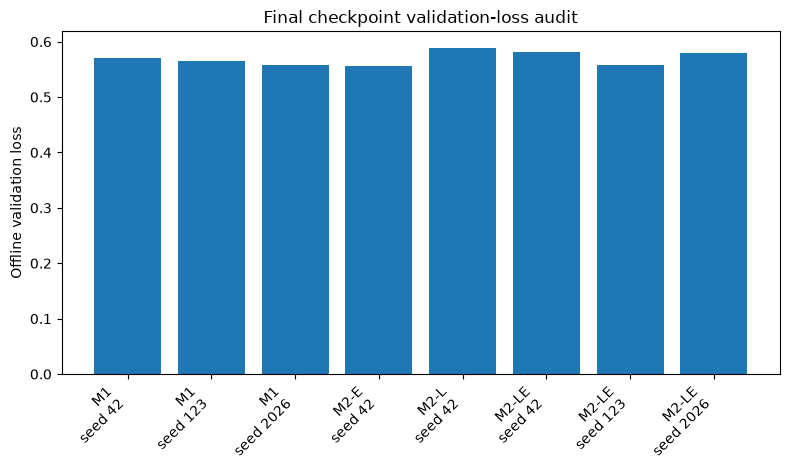

Offline validation is diagnostic only; it is not used to select or reject final checkpoints.


In [16]:
validation_summary_df = (
    final_model_registry_df
    .groupby(
        "variant",
        as_index=False,
    )
    .agg(
        model_count=(
            "seed",
            "count",
        ),
        mean_validation_loss=(
            "validation_loss",
            "mean",
        ),
        sd_validation_loss=(
            "validation_loss",
            "std",
        ),
        min_validation_loss=(
            "validation_loss",
            "min",
        ),
        max_validation_loss=(
            "validation_loss",
            "max",
        ),
    )
)


display(
    validation_summary_df
)


fig, ax = plt.subplots(
    figsize=(
        8,
        4.8,
    )
)

plot_df = (
    final_model_registry_df
    .sort_values(
        [
            "variant",
            "seed",
        ]
    )
    .copy()
)

labels = [
    f"{variant}\nseed {seed}"
    for variant, seed
    in zip(
        plot_df[
            "variant"
        ],
        plot_df[
            "seed"
        ],
    )
]

x = np.arange(
    len(
        plot_df
    )
)

ax.bar(
    x,
    plot_df[
        "validation_loss"
    ],
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    labels,
    rotation=45,
    ha="right",
)

ax.set_ylabel(
    "Offline validation loss"
)

ax.set_title(
    "Final checkpoint validation-loss audit"
)

fig.tight_layout()

validation_figure_path = (
    FIGURES_DIR
    / "final_checkpoint_validation_loss.png"
)

fig.savefig(
    validation_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()


validation_summary_df.to_csv(
    METRICS_DIR
    / "final_checkpoint_validation_summary.csv",
    index=False,
)

print(
    "Offline validation is diagnostic only; "
    "it is not used to select or reject final checkpoints."
)

## 17. Training-compute and parameter audit

In [17]:
new_compute_summary_df = (
    new_training_results_df[
        [
            "variant",
            "seed",
            "training_minutes",
            "peak_gpu_memory_gb",
            "trainable_parameters",
            "total_parameters",
        ]
    ]
    .copy()
)


new_compute_summary_df[
    "trainable_fraction"
] = (
    new_compute_summary_df[
        "trainable_parameters"
    ]
    / new_compute_summary_df[
        "total_parameters"
    ]
)


display(
    new_compute_summary_df
)


assert (
    new_compute_summary_df[
        "trainable_parameters"
    ].nunique()
    == 1
)

assert (
    new_compute_summary_df[
        "total_parameters"
    ].nunique()
    == 1
)


new_compute_summary_df.to_csv(
    METRICS_DIR
    / "final_training_compute_audit.csv",
    index=False,
)


print(
    "Total new GPU training time:",
    f"{new_compute_summary_df['training_minutes'].sum():.1f} min",
)

print(
    "Common trainable parameters:",
    int(
        new_compute_summary_df[
            "trainable_parameters"
        ].iloc[
            0
        ]
    ),
)

print("FINAL TRAINING COMPUTE AUDIT: PASS")

,variant,seed,training_minutes,peak_gpu_memory_gb,trainable_parameters,total_parameters,trainable_fraction
0,M2-L,42,60.511436,2.096672,99880992,450046176,0.221935
1,M2-E,42,61.903013,2.101756,99880992,450046176,0.221935
2,M2-LE,42,63.208444,2.092940,99880992,450046176,0.221935
3,M2-LE,123,63.544577,2.101453,99880992,450046176,0.221935
4,M2-LE,2026,64.631454,2.096365,99880992,450046176,0.221935


Total new GPU training time: 313.8 min
Common trainable parameters: 99880992
FINAL TRAINING COMPUTE AUDIT: PASS


## 18. Language-assignment audit for final language-robust models

The language assignment is part of the experimental evidence and must be preserved.

Expected:

- M2-L seed 42 → L0/L1/L2 only
- M2-LE seed 42 → L0/L1/L2 only
- M2-LE seed 123 → L0/L1/L2 only
- M2-LE seed 2026 → L0/L1/L2 only
- L3 appears zero times in every final training assignment

In [18]:
language_audit_rows = []


language_runs_df = (
    new_training_results_df[
        new_training_results_df[
            "variant"
        ].isin(
            [
                "M2-L",
                "M2-LE",
            ]
        )
    ]
)


for row in (
    language_runs_df.itertuples()
):
    assert row.language_assignment is not None

    assignment_path = (
        REPO_ROOT
        / row.language_assignment
    )

    assert assignment_path.exists()

    assignment_df = pd.read_csv(
        assignment_path
    )

    observed_levels = set(
        assignment_df[
            "language_level"
        ]
    )

    assert observed_levels == {
        "L0",
        "L1",
        "L2",
    }

    assert "L3" not in (
        observed_levels
    )

    counts = (
        assignment_df[
            "language_level"
        ]
        .value_counts()
        .to_dict()
    )

    language_audit_rows.append({
        "variant": str(
            row.variant
        ),
        "seed": int(
            row.seed
        ),
        "episodes": len(
            assignment_df
        ),
        "L0": int(
            counts.get(
                "L0",
                0,
            )
        ),
        "L1": int(
            counts.get(
                "L1",
                0,
            )
        ),
        "L2": int(
            counts.get(
                "L2",
                0,
            )
        ),
        "L3": int(
            counts.get(
                "L3",
                0,
            )
        ),
    })


final_language_audit_df = (
    pd.DataFrame(
        language_audit_rows
    )
)


display(
    final_language_audit_df
)


assert len(
    final_language_audit_df
) == 4

assert (
    final_language_audit_df[
        "L3"
    ]
    == 0
).all()


final_language_audit_df.to_csv(
    METRICS_DIR
    / "final_language_assignment_audit.csv",
    index=False,
)

print("FINAL LANGUAGE ASSIGNMENTS: PASS")

,variant,seed,episodes,L0,L1,L2,L3
0,M2-L,42,346,120,114,112,0
1,M2-LE,42,346,120,114,112,0
2,M2-LE,123,346,120,114,112,0
3,M2-LE,2026,346,112,120,114,0


FINAL LANGUAGE ASSIGNMENTS: PASS


## 19. Freeze the Notebook 07 definitive-evaluation handoff

Notebook 07 must consume the frozen eight-checkpoint registry and must not substitute models based on evaluation outcomes.

The planned evaluation remains:

- E0 ID / L0
- L1 lexical
- L2 syntactic
- L3 held-out compositional language
- seen-family photometric shift
- held-out Gaussian sensor noise
- combined L3 + photometric shift

The main inferential comparison remains **M1 vs M2-LE across seeds 42 / 123 / 2026**.

M2-L and M2-E remain single-seed mechanism ablations.

In [19]:
notebook07_handoff = {
    "source_notebook": (
        "06_validated_final_retraining"
    ),
    "final_model_registry": str(
        registry_path.relative_to(
            REPO_ROOT
        )
    ),
    "final_checkpoint_count": int(
        len(
            final_model_registry_df
        )
    ),
    "final_training_steps": int(
        FINAL_TRAINING_STEPS
    ),
    "training_budget_frozen": True,
    "budget_selection_used_ood_results": False,
    "model_selection_after_ood_forbidden": True,
    "dataset_repo_id": (
        DATASET_REPO_ID
    ),
    "dataset_revision": (
        DATASET_REVISION
    ),
    "base_model_repo_id": (
        BASE_MODEL_REPO_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "primary_variants": [
        "M1",
        "M2-LE",
    ],
    "primary_seeds": [
        42,
        123,
        2026,
    ],
    "ablation_variants": {
        "M2-L": [
            42
        ],
        "M2-E": [
            42
        ],
    },
    "language_training_levels": [
        "L0",
        "L1",
        "L2",
    ],
    "held_out_language_level": (
        "L3"
    ),
    "environment_training_augmentation": (
        M2E_TRANSFORMS
    ),
    "planned_conditions": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
        "E4_COMBINED",
    ],
    "evaluation_principle": (
        "Notebook 07 is the definitive closed-loop evaluation. "
        "No final checkpoint may be replaced after observing OOD results."
    ),
}


notebook07_handoff_path = (
    EXPERIMENT_CONFIG_DIR
    / "notebook07_definitive_evaluation_handoff_v1.json"
)


with open(
    notebook07_handoff_path,
    "w",
) as f:
    json.dump(
        notebook07_handoff,
        f,
        indent=2,
    )


print(
    "Notebook 07 handoff:",
    notebook07_handoff_path,
)

print("NOTEBOOK 07 HANDOFF: FROZEN")

Notebook 07 handoff: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/notebook07_definitive_evaluation_handoff_v1.json
NOTEBOOK 07 HANDOFF: FROZEN


## 20. Final technical status

In [20]:
technical_checks = {
    "Notebook 02 prerequisite":
        (
            notebook02_summary[
                "status"
            ]
            == "PASS"
        ),

    "Notebook 03 prerequisite":
        (
            notebook03_summary[
                "status"
            ]
            == "PASS"
        ),

    "Final budget handoff frozen":
        (
            final_budget_handoff[
                "final_budget_frozen"
            ]
            is True
        ),

    "No further budget search":
        (
            final_budget_handoff[
                "no_further_budget_search"
            ]
            is True
        ),

    "No OOD used for budget selection":
        (
            final_budget_handoff[
                "budget_selection_used_ood_results"
            ]
            is False
        ),

    "Frozen split valid":
        (
            len(
                train_ids
            )
            == 346
            and len(
                validation_ids
            )
            == 86
            and set(
                train_ids
            ).isdisjoint(
                validation_ids
            )
        ),

    "Language specification valid":
        (
            len(
                language_df
            )
            == 40
            and set(
                language_df[
                    "level"
                ]
            )
            == {
                "L0",
                "L1",
                "L2",
                "L3",
            }
        ),

    "Five new robustness runs complete":
        (
            len(
                new_training_results_df
            )
            == 5
            and (
                new_training_results_df[
                    "status"
                ]
                == "PASS"
            ).all()
        ),

    "Three validated M1 checkpoints reused":
        (
            len(
                m1_reuse_df
            )
            == 3
        ),

    "Eight final checkpoints registered":
        (
            len(
                final_model_registry_df
            )
            == 8
        ),

    "All final checkpoints at frozen budget":
        bool(
            (
                final_model_registry_df[
                    "training_steps"
                ]
                == FINAL_TRAINING_STEPS
            ).all()
        ),

    "All validation losses finite":
        bool(
            np.isfinite(
                final_model_registry_df[
                    "validation_loss"
                ]
            ).all()
        ),

    "L3 excluded from final training":
        bool(
            (
                final_language_audit_df[
                    "L3"
                ]
                == 0
            ).all()
        ),

    "Notebook 07 handoff created":
        (
            notebook07_handoff_path.exists()
        ),
}


technical_checks = {
    key: bool(
        value
    )
    for key, value
    in technical_checks.items()
}


technical_status_df = (
    pd.DataFrame(
        [
            {
                "check": key,
                "status": (
                    "PASS"
                    if value
                    else "FAIL"
                ),
            }
            for key, value
            in technical_checks.items()
        ]
    )
)


display(
    technical_status_df
)


NOTEBOOK_06_PASS = bool(
    all(
        technical_checks.values()
    )
)


notebook06_summary = {
    "notebook": (
        "06_validated_final_retraining"
    ),
    "technical_status": (
        "PASS"
        if NOTEBOOK_06_PASS
        else "FAIL"
    ),
    "final_training_steps": int(
        FINAL_TRAINING_STEPS
    ),
    "learning_rate": float(
        LEARNING_RATE
    ),
    "weight_decay": float(
        WEIGHT_DECAY
    ),
    "batch_size": int(
        BATCH_SIZE
    ),
    "new_training_runs": int(
        len(
            new_training_results_df
        )
    ),
    "reused_m1_runs": int(
        len(
            m1_reuse_df
        )
    ),
    "final_checkpoint_count": int(
        len(
            final_model_registry_df
        )
    ),
    "final_model_registry": str(
        registry_path.relative_to(
            REPO_ROOT
        )
    ),
    "notebook07_handoff": str(
        notebook07_handoff_path.relative_to(
            REPO_ROOT
        )
    ),
    "technical_checks": (
        technical_checks
    ),
}


notebook06_summary_path = (
    METRICS_DIR
    / "notebook06_summary.json"
)


with open(
    notebook06_summary_path,
    "w",
) as f:
    json.dump(
        notebook06_summary,
        f,
        indent=2,
    )


print(
    "="
    * 80
)

print(
    "NOTEBOOK 06 — FINAL STATUS"
)

print(
    "="
    * 80
)


for key, value in (
    technical_checks.items()
):
    print(
        f"{key:<62} "
        f"{'PASS' if value else 'FAIL'}"
    )


print(
    "-"
    * 80
)

print(
    f"{'NOTEBOOK 06 TECHNICAL STATUS':<62} "
    f"{'PASS' if NOTEBOOK_06_PASS else 'FAIL'}"
)

print(
    f"{'FROZEN FINAL TRAINING BUDGET':<62} "
    f"{FINAL_TRAINING_STEPS}"
)

print(
    f"{'FINAL CHECKPOINTS':<62} "
    f"{len(final_model_registry_df)}"
)

print(
    f"{'NEW ROBUSTNESS RUNS TRAINED':<62} "
    f"{len(new_training_results_df)}"
)

print(
    f"{'VALIDATED M1 RUNS REUSED':<62} "
    f"{len(m1_reuse_df)}"
)

print(
    "-"
    * 80
)


assert NOTEBOOK_06_PASS, (
    "Notebook 06 contains an incomplete final-training artifact."
)


print()

print(
    "Final model registry:",
    registry_path,
)

print(
    "Notebook 07 handoff:",
    notebook07_handoff_path,
)

print(
    "Summary:",
    notebook06_summary_path,
)

,check,status
0,Notebook 02 prerequisite,PASS
1,Notebook 03 prerequisite,PASS
2,Final budget handoff frozen,PASS
3,No further budget search,PASS
4,No OOD used for budget selection,PASS
5,Frozen split valid,PASS
6,Language specification valid,PASS
7,Five new robustness runs complete,PASS
8,Three validated M1 checkpoints reused,PASS
9,Eight final checkpoints registered,PASS


NOTEBOOK 06 — FINAL STATUS
Notebook 02 prerequisite                                       PASS
Notebook 03 prerequisite                                       PASS
Final budget handoff frozen                                    PASS
No further budget search                                       PASS
No OOD used for budget selection                               PASS
Frozen split valid                                             PASS
Language specification valid                                   PASS
Five new robustness runs complete                              PASS
Three validated M1 checkpoints reused                          PASS
Eight final checkpoints registered                             PASS
All final checkpoints at frozen budget                         PASS
All validation losses finite                                   PASS
L3 excluded from final training                                PASS
Notebook 07 handoff created                                    PASS
---------------------

## 21. Report-ready interpretation

Notebook 06 should be described as the **validated final model-construction stage**.

A concise methodological statement is:

> Following the bounded multi-seed training-budget study, the final optimization regime was frozen before robustness model construction. Three standard M1 checkpoints generated under the validated regime were retained, while M2-L, M2-E and M2-LE were trained under the identical optimization budget. The robustness variants differed only in their predeclared language and/or photometric augmentation. L3 and the held-out visual-noise category remained absent from training. All eight checkpoints were frozen before definitive OOD evaluation.

### What Notebook 06 establishes

- eight final model checkpoints exist;
- all use the same frozen training budget;
- M1 and M2-LE have matched seeds 42 / 123 / 2026;
- M2-L and M2-E provide single-seed ablations;
- L3 was never used for training;
- held-out sensor noise was never used for training;
- all checkpoints reload successfully;
- no OOD result influenced checkpoint selection.

### What Notebook 06 does not establish

It does **not** prove robustness improvement.

The final research claims must come from Notebook 07, where the frozen checkpoints are evaluated under ID and OOD conditions.